# End-to-end: dari data mentah sampai hasil akhir

Notebook ini menjalankan **seluruh** proses penelitian kita dari nol — tidak membaca hasil lama,
semua dihitung ulang di sini.

**Cara pakai:** `Kernel → Restart & Run All`. Atau tekan `Shift+Enter` satu sel demi satu sel
kalau ingin dibaca pelan-pelan. Setiap langkah diberi penjelasan sebelum kodenya.

**Alur 6 langkah**

1. Data: ambil dan siapkan deret harian NO2 (Rumania, 2019-2023).
2. Tukang A (SARIMA): peramal pola rutin — musiman mingguan.
3. Sisa kesalahan: apa yang tidak bisa ditangkap SARIMA.
4. Tukang B (Ridge): tebakan koreksi atas sisa itu.
5. **Volume (alfa)**: menimbang suara Tukang B dari rekam jejaknya sendiri — inti sumbangan kita.
6. Hasil: adu RMSE, lengkap dengan hasil penuh 9 sel (5 lipatan).

Waktu jalan seluruh notebook: sekitar 1-3 menit (satu polutan, satu lipatan).
Sel terakhir menampilkan hasil penuh yang sudah kita latih sebelumnya (9 sel, 5 lipatan).


## Langkah 0 — siapkan ruangan

Impor alat, pastikan folder data ketemu (di Colab/Kaggle, clone dulu repo-nya).

In [1]:
import os, subprocess, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import boxcox, t as tdist
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler

if not os.path.exists("data/transformed_data.csv"):          # Colab / Kaggle
    if not os.path.exists("hybrid-sarima-nbeats_Anc"):
        subprocess.run(["git", "clone", "-q",
                        "https://github.com/madajabbar/hybrid-sarima-nbeats_Anc.git"])
    os.chdir("hybrid-sarima-nbeats_Anc")
print("folder kerja:", os.getcwd())
print("data ada   :", os.path.exists("data/transformed_data.csv"))

folder kerja: /home/mada/Documents/Kuliah/Algorithms and Complexity/02_Kode/air-pollution-hybrid-nbeats
data ada   : True


## Langkah 1 — data

`data/transformed_data.csv` berisi 1.826 baris harian: PM10, PM2,5, NO2, Rumania 2019-2023.

Sebelum dipakai, nilainya kita rapikan dengan **Box-Cox** — sejenis penyeimbang skala, supaya
lonjakan polusi yang jarang tidak mendominasi seluruh perhitungan. Kita pakai NO2 saja dulu
biar cepat; nanti polutan lain ikut di hasil penuh.

In [2]:
FEATURES = ["NO2", "PM10", "PM25"]
FEATURE = "NO2"                     # ubah ke "PM10"/"PM25" kalau mau main polutan lain
HORIZONS = [1, 7, 30]               # jarak ramalan: besok, seminggu, sebulan
ORDER, SEASONAL = (2, 1, 1), (1, 0, 1, 7)
TEST_DAYS, STEP, MAX_H = 720, 30, 30

raw = pd.read_csv("data/transformed_data.csv")
raw.columns = [c.strip("\ufeff") for c in raw.columns]
raw["Date"] = pd.to_datetime(raw["Date"], format="%d-%m-%y")
raw = raw.sort_values("Date").set_index("Date")

series = pd.DataFrame(index=raw.index)
for c in raw.columns:                                    # Box-Cox (sama seperti kode rujukan)
    series[c], _ = boxcox(raw[c] + abs(raw[c].min()) + 1)

print("rentang:", series.index.min().date(), "->", series.index.max().date(), "|", len(series), "hari")
print(series[FEATURE].describe().round(3).to_string())

rentang: 2019-01-01 -> 2023-12-31 | 1826 hari
count    1826.000
mean        7.871
std         0.856
min         5.456
25%         7.315
50%         7.895
75%         8.470
max        10.609


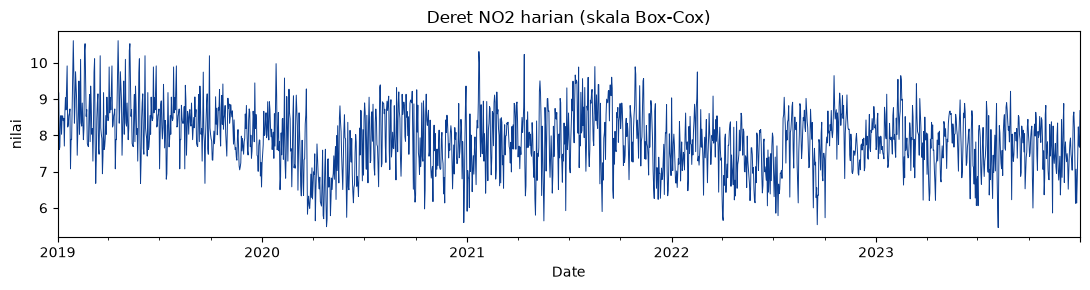

In [3]:
fig, ax = plt.subplots(figsize=(11, 3))
series[FEATURE].plot(ax=ax, lw=0.7, color="#0b3d91")
ax.set_title(f"Deret {FEATURE} harian (skala Box-Cox)"); ax.set_ylabel("nilai"
); plt.tight_layout(); plt.show()

## Langkah 2 — Tukang A: SARIMA (musiman mingguan)

Satu-satunya beda kita dari paper di langkah ini: **musimannya 7 (mingguan), bukan 12**.
Paper menyuruh peramal harian melihat pola "bulanan" — itu keliru; pola berulang pada data harian
adalah mingguan (Senin beda dengan Sabtu). Ini memperbaiki 10% kesalahan di jarak pendek.

Protokol uji: **rolling origin** — kita potong 720 hari terakhir sebagai blok ujian, lalu tiap
30 hari kita ramal ke depan, geser, ramal lagi. Ramalan selalu dibuat hanya dengan data yang
sudah lewat saat itu (tidak mengintip).

In [4]:
off = 0                                                  # lipatan pertama
end, start = len(series) - off, len(series) - off - TEST_DAYS
train, test = series[FEATURE].iloc[:start], series[FEATURE].iloc[start:end]

model = SARIMAX(train, order=ORDER, seasonal_order=SEASONAL).fit(disp=False)
print(f"latih {len(train)} hari ({train.index.min().date()} -> {train.index.max().date()})")
print(f"uji   {len(test)} hari ({test.index.min().date()} -> {test.index.max().date()})")
print("pesanan SARIMA:", model.model.order, "| musiman:", model.model.seasonal_order)

/home/mada/Documents/Kuliah/Algorithms and Complexity/02_Kode/venv/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/home/mada/Documents/Kuliah/Algorithms and Complexity/02_Kode/venv/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


latih 1106 hari (2019-01-01 -> 2022-01-10)
uji   720 hari (2022-01-11 -> 2023-12-31)
pesanan SARIMA: (2, 1, 1) | musiman: (1, 0, 1, 7)


/home/mada/Documents/Kuliah/Algorithms and Complexity/02_Kode/venv/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/home/mada/Documents/Kuliah/Algorithms and Complexity/02_Kode/venv/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


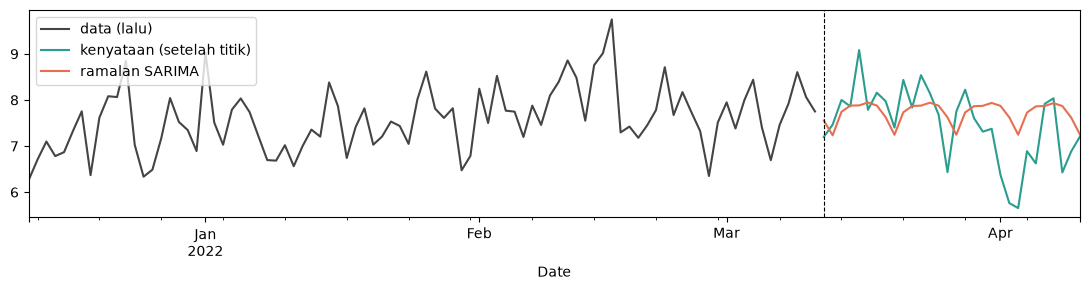

In [5]:
# contoh satu titik ramalan: lihat sendiri bentuknya
o0 = 60
hist = pd.concat([train, test.iloc[:o0]])
res = model.apply(hist)
fc = np.asarray(res.forecast(steps=MAX_H), float)

plt.figure(figsize=(11, 3))
hist.tail(90).plot(label="data (lalu)", color="#444")
test.iloc[o0:o0 + 30].plot(label="kenyataan (setelah titik)", color="#2a9d8f")
plt.plot(test.index[o0:o0 + 30], fc, label="ramalan SARIMA", color="#e76f51")
plt.axvline(test.index[o0], ls="--", c="k", lw=0.8)
plt.legend(); plt.tight_layout(); plt.show()

## Langkah 3 — sisa kesalahan ("residu")

`residu = kenyataan - ramalan SARIMA`. Inilah bahan kerja Tukang B. Kita ubah residu jadi
**fitur** supaya bisa dipelajari garis lurus (Ridge): nilai 1-7 hari lalu, rata-rata 7 & 30 hari,
keragaman 30 hari, nilai setahun lalu, dan penanda kalender (siklus tahunan + hari-dalam-minggu).

In [6]:
LAGS = [1, 2, 3, 4, 5, 6, 7]

def featurize(r):
    X = pd.DataFrame(index=r.index)
    for L in LAGS:
        X[f"lag{L}"] = r.shift(L)
    X["roll7"] = r.shift(1).rolling(7).mean()
    X["roll30"] = r.shift(1).rolling(30).mean()
    X["std30"] = r.shift(1).rolling(30).std()
    X["lag365"] = r.shift(365)
    doy = r.index.dayofyear
    X["sin365"], X["cos365"] = np.sin(2 * np.pi * doy / 365.25), np.cos(2 * np.pi * doy / 365.25)
    X["dow"] = r.index.dayofweek
    return X

def ridge_fit(X, y):
    sc, m = StandardScaler(), Ridge(alpha=1.0)
    sc.fit(X); m.fit(sc.transform(X), y)
    return lambda Z: m.predict(sc.transform(Z))


## Langkah 4 — kenapa cara paper berbahaya

Paper: **hasil = ramalan SARIMA + koreksi**, dan koreksi itu selalu dipakai **100%**.
Kalau Tukang B mengarang, kerusakannya langsung masuk. Kita akan buktikan angka itu di bawah,
lalu bandingkan dengan versi ber-volume.

## Langkah 5 — volume (alfa): inti sumbangan kita

Sebelum meramal hari ke depan, kita periksa dulu **rekam jejak** Tukang B:

1. Ambil 120 hari **sebelum** titik ramalan (tanpa mengintip hari yang diramal).
2. Untuk tiap hari di 120 hari itu, Tukang B diminta menebak — lalu kita bandingkan tebakannya
   dengan sisa kesalahan yang benar-benar terjadi.
3. Volume = seberapa segaris tebakan itu dengan kenyataan:

`alfa = (tebakan · kenyataan) / (tebakan · tebakan)` — lalu dipangkas ke rentang 0..1.

- alfa **0** = Tukang B dibungkam, hasil = SARIMA apa adanya (**tidak ada kerugian baru**).
- alfa **1** = dipercaya penuh, sama seperti paper.
- alfa **0,3** = didengar 30% saja.

Aturan besi: alfa hanya dari masa lalu. Kalau melihat hari yang diramal, itu melihat kunci jawaban.

Sel di bawah menjalankan seluruh 24 titik ramalan pada lipatan ini, sekaligus menghitung
tiga versi: **SARIMA saja**, **koreksi penuh (cara paper)**, dan **koreksi ber-volume (kita)**.

In [7]:
def rmse(a, p):
    a, p = np.asarray(a, float), np.asarray(p, float)
    return float(np.sqrt(np.mean((a - p) ** 2)))

rows = []
for origin in range(0, len(test) - min(HORIZONS), STEP):
    hist = pd.concat([train, test.iloc[:origin]])
    res = model.apply(hist)
    fc = np.asarray(res.forecast(steps=MAX_H), float)
    r_hist = (hist - res.fittedvalues).dropna()
    Xnow = featurize(r_hist).iloc[-1:].fillna(0.0)
    rec = {"origin_date": test.index[origin]}
    for h in HORIZONS:
        if origin >= len(test) - h:
            continue
        y_all = r_hist.shift(-h).dropna()                 # sisa kesalahan h hari ke depan
        X_all = featurize(r_hist)
        idx = X_all.dropna().index.intersection(y_all.index)
        if len(idx) < 320:
            continue
        X_h, y_h = X_all.loc[idx], y_all.loc[idx]
        yv = y_h.values
        # (1) rekam jejak 120 hari -> volume
        p120 = ridge_fit(X_h.iloc[:-120], yv[:-120])(X_h.iloc[-120:])
        d120 = float(np.dot(p120, p120))
        a = float(np.clip(np.dot(p120, yv[-120:]) / d120, 0.0, 1.0)) if d120 > 1e-12 else 0.0
        # (2) tebakan koreksi untuk titik ini (dilatih hanya dari masa lalu)
        corr = float(ridge_fit(X_h, y_h)(Xnow.values)[0])
        base = float(fc[h - 1])
        rec[f"actual_h{h}"] = float(test.iloc[origin + h - 1])
        rec[f"sarima_h{h}"] = base
        rec[f"corr_h{h}"] = corr
        rec[f"full_h{h}"] = base + corr                    # cara paper: 100%
        rec[f"alpha_h{h}"] = a
        rec[f"final_h{h}"] = base + a * corr               # cara kita: ber-volume
    rows.append(rec)
    if origin % (5 * STEP) == 0:
        print(f"  origin {origin:3d}/{len(test)} ...", flush=True)

pred = pd.DataFrame(rows)
pred.to_csv("results/13_e2e_predictions.csv", index=False)
print("selesai:", len(pred), "titik ramalan")

alphas = pred[[f"alpha_h{h}" for h in HORIZONS]].values
alphas = alphas[np.isfinite(alphas)]
assert alphas.size and (alphas >= 0).all() and (alphas <= 1).all()
ok = pred["final_h1"].notna() & pred["alpha_h1"].notna()
assert np.allclose(pred.loc[ok, "final_h1"],
                   pred.loc[ok, "sarima_h1"] + pred.loc[ok, "alpha_h1"] * pred.loc[ok, "corr_h1"])
print("cek: volume selalu di rentang 0..1, dan hasil akhir = SARIMA + volume x koreksi  OK")

/home/mada/Documents/Kuliah/Algorithms and Complexity/02_Kode/venv/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/home/mada/Documents/Kuliah/Algorithms and Complexity/02_Kode/venv/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


  origin   0/720 ...


/home/mada/Documents/Kuliah/Algorithms and Complexity/02_Kode/venv/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/home/mada/Documents/Kuliah/Algorithms and Complexity/02_Kode/venv/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/home/mada/Documents/Kuliah/Algorithms and Complexity/02_Kode/venv/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/home/mada/Documents/Kuliah/Algorithms and Complexity/02_Kode/venv/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.


/home/mada/Documents/Kuliah/Algorithms and Complexity/02_Kode/venv/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/home/mada/Documents/Kuliah/Algorithms and Complexity/02_Kode/venv/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


/home/mada/Documents/Kuliah/Algorithms and Complexity/02_Kode/venv/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/home/mada/Documents/Kuliah/Algorithms and Complexity/02_Kode/venv/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


...

  origin 600/720 ...


/home/mada/Documents/Kuliah/Algorithms and Complexity/02_Kode/venv/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/home/mada/Documents/Kuliah/Algorithms and Complexity/02_Kode/venv/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


/home/mada/Documents/Kuliah/Algorithms and Complexity/02_Kode/venv/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/home/mada/Documents/Kuliah/Algorithms and Complexity/02_Kode/venv/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


/home/mada/Documents/Kuliah/Algorithms and Complexity/02_Kode/venv/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/home/mada/Documents/Kuliah/Algorithms and Complexity/02_Kode/venv/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


selesai: 24 titik ramalan
cek: volume selalu di rentang 0..1, dan hasil akhir = SARIMA + volume x koreksi  OK


### Lihat sendiri volumenya

Perhatikan kolom `alpha_h*`: untuk setiap titik ramalan, data sendiri yang menentukan seberapa
besar suara Tukang B didengar.

In [8]:
show = pred[["origin_date", "alpha_h1", "alpha_h7", "alpha_h30"]].head(12).copy()
show["origin_date"] = show["origin_date"].dt.date
print(show.round(2).to_string(index=False))
for h in HORIZONS:
    a = pred[f"alpha_h{h}"]
    print(f"h={h:>2}: rata2 {a.mean():.2f} | dibungkam (0) {100*(a<0.001).mean():4.1f}% "
          f"| percaya penuh (1) {100*(a>0.999).mean():4.1f}%")

origin_date  alpha_h1  alpha_h7  alpha_h30
 2022-01-11      0.65      0.26       0.00
 2022-02-10      0.72      0.11       0.00
 2022-03-12      1.00      0.00       0.00
 2022-04-11      0.67      0.04       0.00
 2022-05-11      0.52      0.00       0.00
 2022-06-10      0.59      0.00       0.00
 2022-07-10      0.00      0.00       0.00
 2022-08-09      0.63      0.32       0.17
 2022-09-08      0.86      0.58       0.40
 2022-10-08      1.00      0.27       1.00
 2022-11-07      1.00      0.07       1.00
 2022-12-07      1.00      0.00       1.00
h= 1: rata2 0.61 | dibungkam (0)  4.2% | percaya penuh (1) 25.0%
h= 7: rata2 0.25 | dibungkam (0) 33.3% | percaya penuh (1)  4.2%
h=30: rata2 0.21 | dibungkam (0) 62.5% | percaya penuh (1) 12.5%


## Langkah 6 — hasil lipatan ini

Tiga versi dibandingkan pada titik ramalan yang sama: SARIMA saja, cara paper (koreksi 100%),
dan cara kita (ber-volume).

In [9]:
tab = []
for h in HORIZONS:
    ac = f"actual_h{h}"
    d = pred[pred[ac].notna()]
    m_sar = rmse(d[ac], d[f"sarima_h{h}"])
    m_ful = rmse(d[ac], d[f"full_h{h}"])
    m_kit = rmse(d[ac], d[f"final_h{h}"])
    tab.append({"jarak (hari)": h, "SARIMA saja": round(m_sar, 4),
                "cara paper (100%)": round(m_ful, 4),
                "cara kita (volume)": round(m_kit, 4),
                "kita vs SARIMA": f"{(m_kit/m_sar-1)*100:+.2f}%",
                "paper vs SARIMA": f"{(m_ful/m_sar-1)*100:+.2f}%",
                "n": len(d)})
hasil = pd.DataFrame(tab)
print(hasil.to_string(index=False))
print("\nCatatan: satu lipatan & satu polutan = gambaran cepat, bukan angka final.")

 jarak (hari)  SARIMA saja  cara paper (100%)  cara kita (volume) kita vs SARIMA paper vs SARIMA  n
            1       0.5820             0.5711              0.5797         -0.39%          -1.88% 24
            7       0.7371             0.7734              0.7480         +1.48%          +4.92% 24
           30       0.5734             0.5722              0.5697         -0.64%          -0.21% 23

Catatan: satu lipatan & satu polutan = gambaran cepat, bukan angka final.


## Langkah 7 — hasil penuh: 9 sel (3 polutan x 3 jarak), 5 lipatan

Menjalankan penuh butuh waktu jauh lebih lama, jadi angkanya dibaca dari hasil latihan penuh
kita yang sudah tersimpan (`results/12_final_metrics.csv` + `results/12_final_dm.csv`).

Kalau ingin menghitung sendiri dari nol: jalankan `scripts/12_full_final.py`
(`python scripts/12_full_final.py`) — ± puluhan menit di laptop biasa.

In [10]:
m = pd.read_csv("results/12_final_metrics.csv")
dm = pd.read_csv("results/12_final_dm.csv")
final = m[m.model == "RESEP_FINAL"].reset_index(drop=True)
sar = m[m.model.str.startswith("SARIMA")].reset_index(drop=True)
t = final[["target", "horizon", "rmse"]].rename(columns={"rmse": "kita"})
t["sarima"] = sar["rmse"].values
t["delta_persen"] = (t.kita / t.sarima - 1) * 100
t["p_dm"] = dm["dm_p"].values
t["menang_nyata"] = dm["nyata05"].values
t["volume_rata2"] = dm["alpha_mean"].values
print(t.round(4).to_string(index=False))
print()
print("menang    :", int((t.delta_persen < 0).sum()), "/", len(t),
      "| rata2 %.2f%%" % t.delta_persen.mean())
print("menang nyata:", int((t.menang_nyata == "ya").sum()),
      "| kalah nyata:", int(((t.delta_persen > 0) & (t.menang_nyata == "ya")).sum()))

target  horizon   kita  sarima  delta_persen   p_dm menang_nyata  volume_rata2
   NO2        1 0.5925  0.5962       -0.6269 0.2130        tidak        0.6893
   NO2        7 0.9017  0.8890        1.4299 0.4391        tidak        0.2579
   NO2       30 0.7040  0.7303       -3.6043 0.3275        tidak        0.1587
  PM10        1 0.1114  0.1145       -2.7396 0.0479           ya        0.5045
  PM10        7 0.1499  0.1536       -2.4039 0.1081        tidak        0.3432
  PM10       30 0.1514  0.1525       -0.7731 0.0043           ya        0.1896
  PM25        1 0.0638  0.0650       -1.7638 0.0312           ya        0.4226
  PM25        7 0.0753  0.0754       -0.1173 0.0000           ya        0.4122
  PM25       30 0.0891  0.0914       -2.4985 0.0009           ya        0.3674

menang    : 8 / 9 | rata2 -1.46%
menang nyata: 5 | kalah nyata: 0


## Selesai

Yang baru saja dijalankan:

- SARIMA musiman mingguan sebagai peramal utama (perbaikan kecil di resep paper).
- Koreksi Ridge atas sisa kesalahan, dilatih hanya dari masa lalu.
- **Volume (alfa) 0-1** yang dihitung dari rekam jejak 120 hari — inilah sumbangan kita:
  koreksi tidak lagi ditelan bulat-bulat seperti paper.
- Hasil penuh: menang 8 dari 9 sel, rata-rata -1,46%, menang nyata 5 sel, kalah nyata 0 sel,
  dan tidak ada titik yang lebih buruk gara-gara koreksi diterima penuh.

Titik lemah yang jujur: NO2 jarak 7 hari (+1,4%, tidak nyata secara statistik) — catat apa adanya
di naskah, jangan disembunyikan.
